# Comparación de detectores sobre el dataset del obligatorio

IsolationForest y One-Class SVM con núcleo RBF sobre el dataset sintético que dieron los docentes para el obligatorio, con k-sigma y MAD como línea base. El dataset trae etiquetas (`kind`, `is_anomaly`), así que acá se puede medir lo que con un dataset real sin etiquetas solo se puede rankear.

Cada fila es un minuto de un servicio de checkout con cuatro features: `requests`, `error_rate`, `latency_ms` y `cpu_pct`. En condiciones normales las cuatro se mueven juntas con la carga. Las anomalías son de cuatro tipos:

1. Fáciles: un eje se dispara (`micro_burst`, `incidente_5xx`).
2. Combinaciones raras: ningún eje es extremo, la combinación sí (`combo_sutil`).
3. Trampas operativas, que **no** son incidentes: `batch` (CPU alta legítima) y `pico_carga` (mucho tráfico, sobre la relación habitual).
4. Una degradación lenta y spikes de error rate.

Protocolo (el que pide el cuaderno de los docentes):

- Entrenamiento sin etiquetas, sobre las 300 ventanas, con la muestra contaminada.
- IF y OCSVM sobre las cuatro features escaladas. `contamination=0.10` y `nu=0.10` son un presupuesto de unas 30 alertas, no la tasa real (17,7%).
- Score: mayor es más anómalo (`-decision_function`). Flag: score positivo, equivalente a `predict == -1`.
- Las etiquetas se usan solo para evaluar.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import HuberRegressor

from anomaly_detection.baselines import fit_k_sigma, fit_mad
from anomaly_detection.detectors import detect, fit_isolation_forest, fit_one_class_svm
from anomaly_detection.evaluation import alerts_by_group, classification_metrics, first_alert
from anomaly_detection.synthetic import FEATURES, generate_dataset

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.float_format", "{:.3f}".format)

KIND_COLORS = {
    "normal": "#183B66", "batch": "#00A6A6", "pico_carga": "#2A9D8F", "spike_error": "#C9A227",
    "incidente_5xx": "#E76F51", "timeouts": "#8E5BA6", "latencia_silenciosa": "#D62828",
    "combo_sutil": "#9B2226", "degradacion": "#BC6C25", "cpu_latencia": "#6A4C93", "micro_burst": "#F4A261",
}

## 1. Datos

In [2]:
data = generate_dataset(seed=42)
print(f"Ventanas: {len(data)}  |  anómalas: {data.is_anomaly.sum()} ({data.is_anomaly.mean():.1%})")
display(data.groupby("kind")[FEATURES].mean())

Ventanas: 300  |  anómalas: 53 (17.7%)


,requests,error_rate,latency_ms,cpu_pct
kind,,,,
batch,121.750,0.009,92.201,75.925
combo_sutil,54.571,0.014,122.551,24.982
cpu_latencia,139.000,0.010,205.789,86.313
degradacion,144.722,0.010,154.781,40.230
incidente_5xx,36.750,0.042,235.876,36.217
latencia_silenciosa,158.333,0.010,213.073,43.764
micro_burst,123.500,0.063,277.415,37.104
normal,131.137,0.009,96.067,38.424
pico_carga,173.875,0.012,104.374,46.033


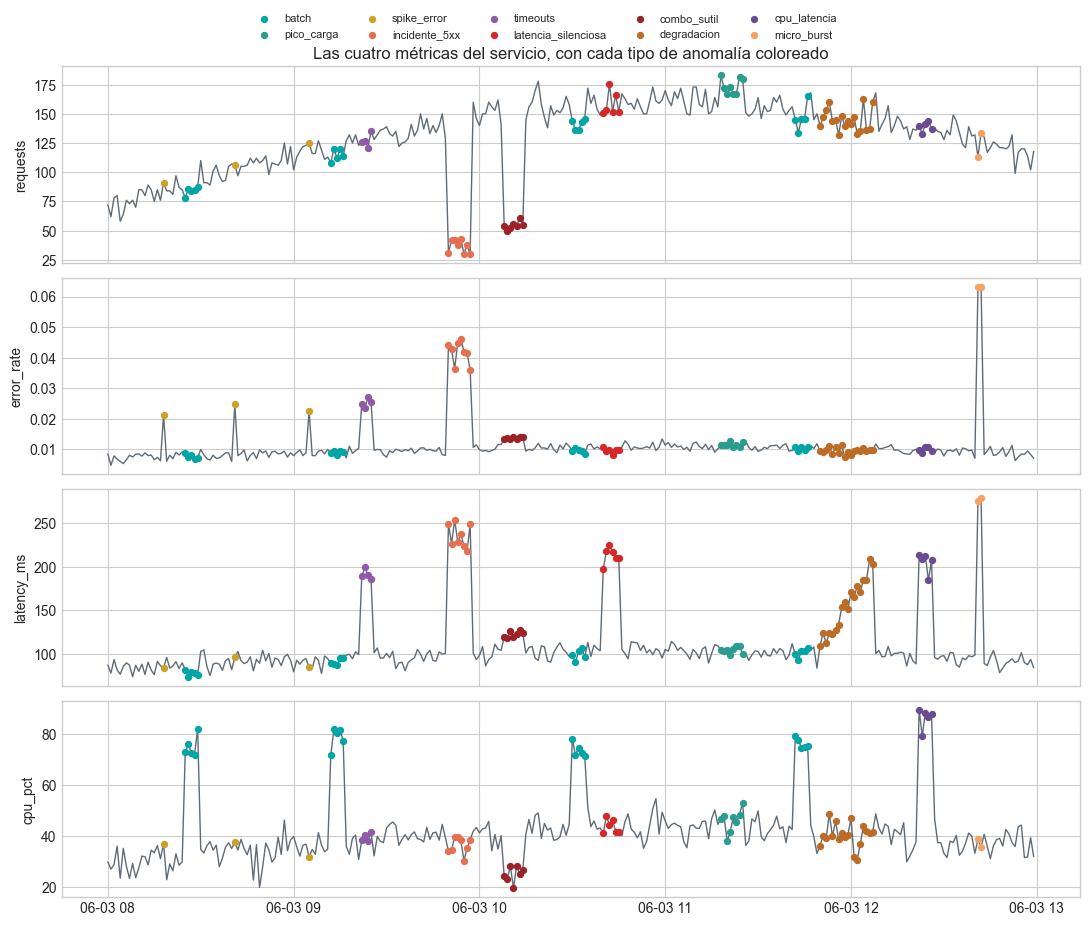

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, column in zip(axes, FEATURES):
    ax.plot(data["timestamp"], data[column], color="#5F6B76", lw=1.0)
    for kind, color in KIND_COLORS.items():
        if kind == "normal":
            continue
        in_kind = data["kind"].eq(kind)
        ax.scatter(data.loc[in_kind, "timestamp"], data.loc[in_kind, column], c=color, s=18, zorder=3, label=kind)
    ax.set_ylabel(column)
axes[0].set_title("Las cuatro métricas del servicio, con cada tipo de anomalía coloreado")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.03), fontsize=8)
plt.tight_layout()
plt.show()

## 2. Detectores

Cuatro univariados (k-sigma y MAD, sobre `error_rate` y `latency_ms`, con $k=3$) y dos multivariados sobre las cuatro features.

In [4]:
baselines = {"k-sigma": fit_k_sigma, "MAD": fit_mad}
univariate_columns = {"error": "error_rate", "lat": "latency_ms"}

scores, flags = {}, {}
for baseline_name, fit in baselines.items():
    for short_name, column in univariate_columns.items():
        baseline = fit(data[column])
        scores[f"{baseline_name} {short_name}"] = baseline.score(data[column])
        flags[f"{baseline_name} {short_name}"] = baseline.flag(data[column])
        print(f"{baseline_name:8} {column:11} centro={baseline.center:.4f}  escala={baseline.scale:.4f}  "
              f"umbral superior={baseline.center + 3 * baseline.scale:.4f}")

multivariate = {"IF": fit_isolation_forest(data[FEATURES]), "OCSVM": fit_one_class_svm(data[FEATURES])}
for name, model in multivariate.items():
    detection = detect(model, data[FEATURES])
    scores[name], flags[name] = detection.score, detection.flag

scores, flags = pd.DataFrame(scores), pd.DataFrame(flags)

k-sigma  error_rate  centro=0.0112  escala=0.0072  umbral superior=0.0328
k-sigma  latency_ms  centro=110.4651  escala=38.5447  umbral superior=226.0993
MAD      error_rate  centro=0.0097  escala=0.0016  umbral superior=0.0144
MAD      latency_ms  centro=99.2228  escala=11.6201  umbral superior=134.0830


## 3. Comparación

Minutos alertados por tipo. `batch`, `pico_carga` y `normal` son falsos positivos.

In [5]:
display(alerts_by_group(data["kind"], flags))

,minutes,k-sigma error,k-sigma lat,MAD error,MAD lat,IF,OCSVM
kind,,,,,,,
batch,20,0,0,0,0,4,5
combo_sutil,7,0,0,0,0,4,1
cpu_latencia,5,0,0,0,5,5,3
degradacion,18,0,0,0,11,0,1
incidente_5xx,8,8,6,8,8,8,4
latencia_silenciosa,6,0,0,0,6,1,3
micro_burst,2,2,2,2,2,2,2
normal,219,0,0,1,0,2,4
pico_carga,8,0,0,0,0,0,2


Métricas sobre las 300 ventanas. La average precision mide el ranking del score, sin depender del umbral.

In [6]:
metrics = pd.DataFrame({
    name: classification_metrics(data["is_anomaly"], flags[name], scores[name]) for name in flags
}).T
display(metrics)

,precision,recall,f1,average_precision,alerts
k-sigma error,1.000,0.189,0.317,0.486,10.000
k-sigma lat,1.000,0.151,0.262,0.775,8.000
MAD error,0.944,0.321,0.479,0.549,18.000
MAD lat,1.000,0.679,0.809,0.937,36.000
IF,0.800,0.453,0.578,0.769,30.000
OCSVM,0.621,0.340,0.439,0.579,29.000


Mediana del score por tipo: el ranking, más allá de la flag.

In [7]:
display(scores.groupby(data["kind"]).median())

,k-sigma error,k-sigma lat,MAD error,MAD lat,IF,OCSVM
kind,,,,,,
batch,0.244,0.427,0.583,0.683,-0.045,-0.136
combo_sutil,0.358,0.334,2.608,2.076,0.002,-0.138
cpu_latencia,0.184,2.569,0.639,9.488,0.060,0.000
degradacion,0.239,1.199,0.340,4.944,-0.089,-0.458
incidente_5xx,4.317,3.191,21.011,11.552,0.099,0.011
latencia_silenciosa,0.185,2.677,0.106,9.847,-0.027,-0.000
micro_burst,7.200,4.331,34.408,15.335,0.177,1.709
normal,0.218,0.362,0.623,0.536,-0.166,-0.512
pico_carga,0.045,0.154,1.050,0.458,-0.124,-0.197


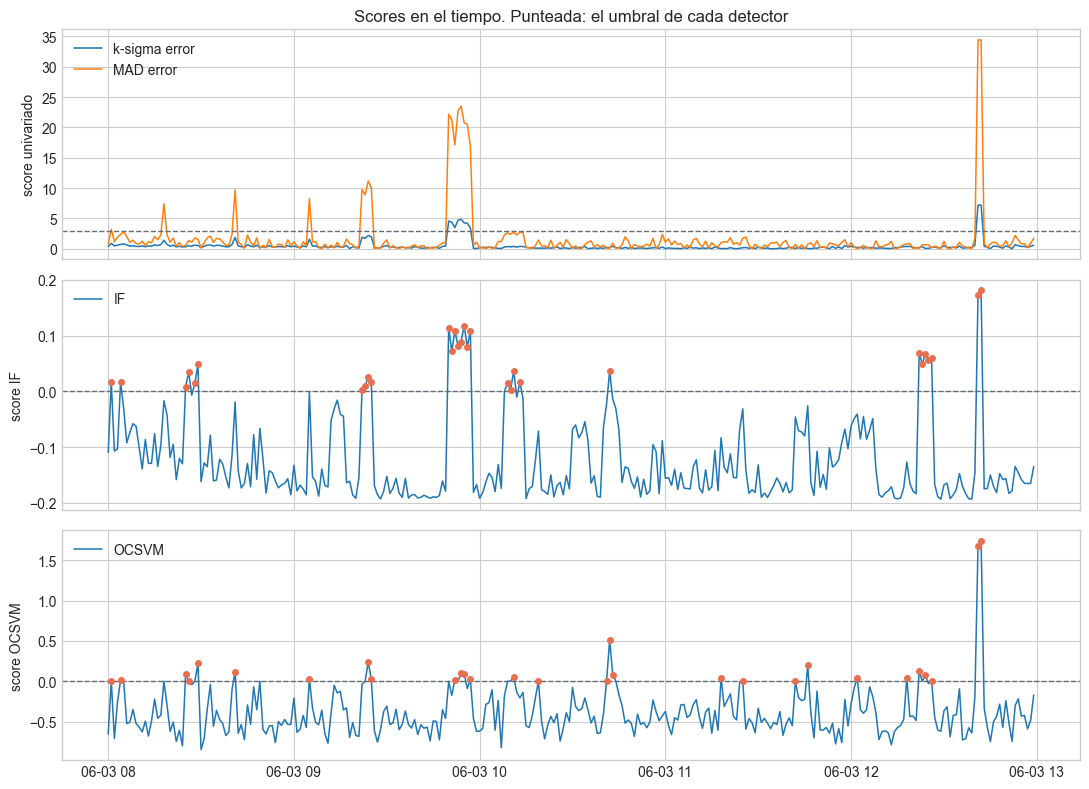

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(data["timestamp"], scores["k-sigma error"], lw=1.1, label="k-sigma error")
axes[0].plot(data["timestamp"], scores["MAD error"], lw=1.1, label="MAD error")
axes[0].axhline(3, color="#5F6B76", ls="--", lw=1)
axes[0].set_ylabel("score univariado")
axes[0].legend(loc="upper left")
for ax, name in zip(axes[1:], ("IF", "OCSVM")):
    ax.plot(data["timestamp"], scores[name], lw=1.1, label=name)
    ax.scatter(data.loc[flags[name], "timestamp"], scores.loc[flags[name], name], c="#E76F51", s=16, zorder=3)
    ax.axhline(0, color="#5F6B76", ls="--", lw=1)
    ax.set_ylabel(f"score {name}")
    ax.legend(loc="upper left")
axes[0].set_title("Scores en el tiempo. Punteada: el umbral de cada detector")
plt.tight_layout()
plt.show()

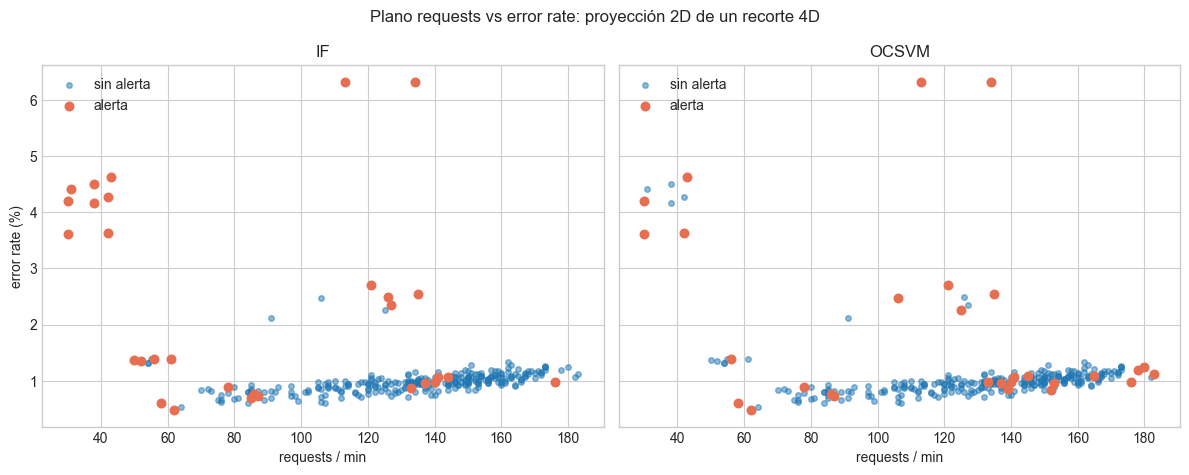

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, name in zip(axes, ("IF", "OCSVM")):
    flagged = flags[name]
    ax.scatter(data.loc[~flagged, "requests"], 100 * data.loc[~flagged, "error_rate"], s=16, alpha=0.5, label="sin alerta")
    ax.scatter(data.loc[flagged, "requests"], 100 * data.loc[flagged, "error_rate"], c="#E76F51", s=38, label="alerta")
    ax.set_title(name)
    ax.set_xlabel("requests / min")
    ax.legend(loc="upper left")
axes[0].set_ylabel("error rate (%)")
plt.suptitle("Plano requests vs error rate: proyección 2D de un recorte 4D")
plt.tight_layout()
plt.show()

### Fronteras en el plano requests contra error rate

Para dibujar la frontera hace falta un plano, así que acá cada detector se entrena solo con `requests` y `error_rate`, con el mismo presupuesto. El color es el score en cada punto del plano y la línea negra es score = 0: afuera de ella, alerta. En OCSVM se marcan los support vectors, los minutos que definen la frontera. Al ser modelos de dos features, sus alertas no coinciden exactamente con las de los modelos de cuatro.

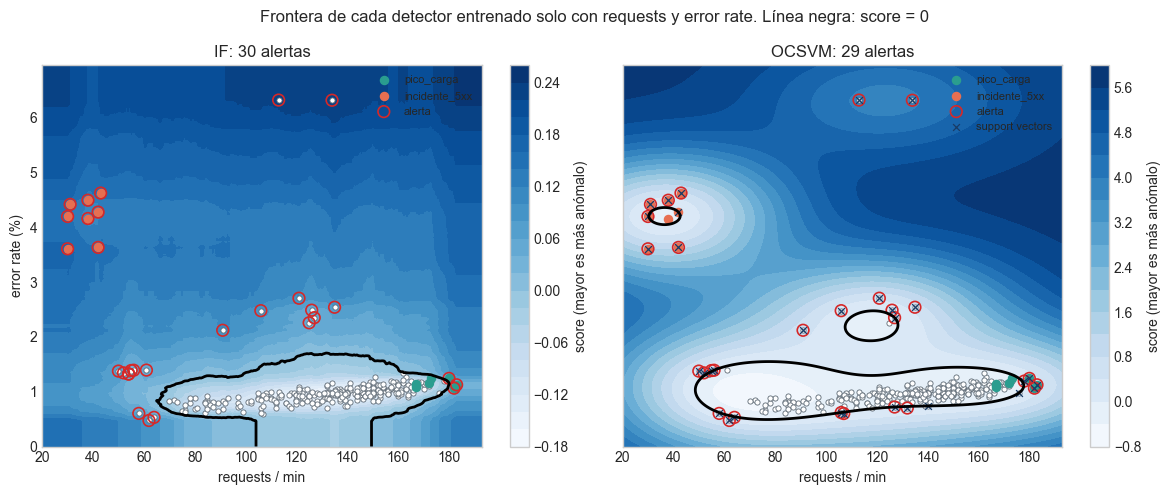

In [10]:
plane = ["requests", "error_rate"]
plane_models = {
    "IF": fit_isolation_forest(data[plane]),
    "OCSVM": fit_one_class_svm(data[plane]),
}

grid_requests, grid_error = np.meshgrid(
    np.linspace(data["requests"].min() - 10, data["requests"].max() + 10, 300),
    np.linspace(0, data["error_rate"].max() * 1.1, 300),
)
grid = pd.DataFrame({"requests": grid_requests.ravel(), "error_rate": grid_error.ravel()})
highlighted_kinds = ("pico_carga", "incidente_5xx")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, plane_models.items()):
    grid_score = detect(model, grid).score.to_numpy().reshape(grid_requests.shape)
    filled = ax.contourf(grid_requests, 100 * grid_error, grid_score, levels=20, cmap="Blues")
    ax.contour(grid_requests, 100 * grid_error, grid_score, levels=[0], colors="black", linewidths=2)
    plane_flag = detect(model, data[plane]).flag
    ax.scatter(data["requests"], 100 * data["error_rate"], c="white", edgecolors="#5F6B76", s=14, lw=0.6)
    for kind in highlighted_kinds:
        in_kind = data["kind"].eq(kind)
        ax.scatter(data.loc[in_kind, "requests"], 100 * data.loc[in_kind, "error_rate"], c=KIND_COLORS[kind], s=34, label=kind)
    ax.scatter(data.loc[plane_flag, "requests"], 100 * data.loc[plane_flag, "error_rate"], facecolors="none", edgecolors="#D62828", s=70, lw=1.2, label="alerta")
    if name == "OCSVM":
        scaler, svm = model.steps[0][1], model.steps[-1][1]
        support_vectors = scaler.inverse_transform(svm.support_vectors_)
        ax.scatter(support_vectors[:, 0], 100 * support_vectors[:, 1], marker="x", c="#183B66", s=24, lw=0.9, label="support vectors")
    ax.set_title(f"{name}: {int(plane_flag.sum())} alertas")
    ax.set_xlabel("requests / min")
    ax.legend(loc="upper right", fontsize=8)
    fig.colorbar(filled, ax=ax, label="score (mayor es más anómalo)")
axes[0].set_ylabel("error rate (%)")
plt.suptitle("Frontera de cada detector entrenado solo con requests y error rate. Línea negra: score = 0")
plt.tight_layout()
plt.show()

Las dos fronteras siguen la nube normal, que crece con la carga. El pico de carga queda en el borde derecho, y en este plano los dos detectores alertan 3 de sus 8 minutos. El incidente 5xx, con poco tráfico y mucho error, queda lejos de la nube: IF lo alerta entero, porque todo lo que está lejos se aísla rápido. OCSVM, en cambio, dibuja una isla cerrada alrededor de esos 8 minutos y deja 2 adentro. El núcleo RBF trata un grupo denso como un modo normal más, aunque esté lejos de la nube, y es la misma geometría que explica por qué con las cuatro features OCSVM alerta solo 4 de los 8 minutos del incidente. La frontera de OCSVM también se ajusta a detalles locales: arma otra isla cerca de 120 requests y 2% de error, sin ningún minuto adentro, y alerta 8 minutos normales contra 3 de IF.

## 4. Sensibilidad a los hiperparámetros

### Presupuesto de alertas (`contamination` y `nu`)

In [11]:
def evaluate(model, features):
    detection = detect(model, features)
    return classification_metrics(data["is_anomaly"], detection.flag, detection.score)


budgets = [0.05, 0.10, 0.15, 0.20, 0.25]
budget_sweep = pd.DataFrame(
    [
        {"detector": "IF", "budget": budget, **evaluate(fit_isolation_forest(data[FEATURES], contamination=budget), data[FEATURES])}
        for budget in budgets
    ] + [
        {"detector": "OCSVM", "budget": budget, **evaluate(fit_one_class_svm(data[FEATURES], nu=budget), data[FEATURES])}
        for budget in budgets
    ]
)
display(budget_sweep.pivot(index="budget", columns="detector", values=["f1", "average_precision", "alerts"]))

f1       average_precision       alerts       
detector    IF OCSVM                IF OCSVM     IF  OCSVM
budget                                                    
0.050    0.441 0.319             0.769 0.553 15.000 16.000
0.100    0.578 0.439             0.769 0.579 30.000 29.000
0.150    0.673 0.592             0.769 0.605 45.000 45.000
0.200    0.690 0.637             0.769 0.697 60.000 60.000
0.250    0.656 0.636             0.769 0.742 75.000 76.000

### `gamma` del núcleo RBF

In [12]:
gammas = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, "scale"]
gamma_sweep = pd.DataFrame(
    [{"gamma": str(gamma), **evaluate(fit_one_class_svm(data[FEATURES], gamma=gamma), data[FEATURES])} for gamma in gammas]
).set_index("gamma")
display(gamma_sweep)

,precision,recall,f1,average_precision,alerts
gamma,,,,,
0.01,0.484,0.283,0.357,0.403,31.000
0.05,0.581,0.340,0.429,0.487,31.000
0.1,0.677,0.396,0.500,0.567,31.000
0.25,0.621,0.340,0.439,0.579,29.000
0.5,0.714,0.377,0.494,0.561,28.000
1.0,0.567,0.321,0.410,0.471,30.000
scale,0.621,0.340,0.439,0.579,29.000


## 5. Features derivadas

Las anomalías difíciles no son valores grandes: son desvíos de la relación con la carga. Se prueba reemplazar cada métrica por su residuo contra `requests`, con una regresión de Huber (robusta a la contaminación), y sumar la mediana móvil de 5 minutos del residuo de latencia para darle memoria al detector.

In [13]:
def load_residual(column):
    regression = HuberRegressor().fit(data[["requests"]], data[column])
    return data[column] - regression.predict(data[["requests"]])


derived = pd.DataFrame({
    "requests": data["requests"],
    "error_residual": load_residual("error_rate"),
    "latency_residual": load_residual("latency_ms"),
    "cpu_residual": load_residual("cpu_pct"),
})
derived["latency_residual_trend"] = derived["latency_residual"].rolling(5, min_periods=1).median()

feature_sets = {
    "crudas": (data, FEATURES),
    "residuos": (derived, ["requests", "error_residual", "latency_residual", "cpu_residual"]),
    "residuos + tendencia": (derived, list(derived.columns)),
}
derived_flags, derived_metrics = {}, {}
for set_name, (frame, columns) in feature_sets.items():
    for name, fit in (("IF", fit_isolation_forest), ("OCSVM", fit_one_class_svm)):
        detection = detect(fit(frame[columns]), frame[columns])
        derived_flags[f"{name} {set_name}"] = detection.flag
        derived_metrics[f"{name} {set_name}"] = classification_metrics(data["is_anomaly"], detection.flag, detection.score)

display(pd.DataFrame(derived_metrics).T)
display(alerts_by_group(data["kind"], pd.DataFrame(derived_flags)))

,precision,recall,f1,average_precision,alerts
IF crudas,0.800,0.453,0.578,0.769,30.000
OCSVM crudas,0.621,0.340,0.439,0.579,29.000
IF residuos,0.867,0.491,0.627,0.786,30.000
OCSVM residuos,0.645,0.377,0.476,0.565,31.000
IF residuos + tendencia,0.867,0.491,0.627,0.836,30.000
OCSVM residuos + tendencia,0.548,0.321,0.405,0.529,31.000


,minutes,IF crudas,OCSVM crudas,IF residuos,OCSVM residuos,IF residuos + tendencia,OCSVM residuos + tendencia
kind,,,,,,,
batch,20,4,5,4,3,2,4
combo_sutil,7,4,1,5,2,6,0
cpu_latencia,5,5,3,5,3,5,3
degradacion,18,0,1,0,1,0,0
incidente_5xx,8,8,4,8,4,8,7
latencia_silenciosa,6,1,3,1,3,3,3
micro_burst,2,2,2,2,2,2,2
normal,219,2,4,0,5,2,9
pico_carga,8,0,2,0,3,0,1


## 6. Preguntas del cuaderno

Evidencia para la pregunta 3: score MAD máximo de `combo_sutil` en cada eje, y su posición en el ranking de IF y OCSVM (1 = más anómalo de las 300 ventanas).

In [14]:
is_combo = data["kind"].eq("combo_sutil")
display(pd.Series({column: fit_mad(data[column]).score(data[column])[is_combo].max() for column in FEATURES}, name="máx. score MAD"))
multivariate_rank = scores[["IF", "OCSVM"]].rank(ascending=False).astype(int)
display(multivariate_rank.loc[is_combo].assign(timestamp=data["timestamp"]).set_index("timestamp"))
display(multivariate_rank.loc[data["kind"].eq("pico_carga")].agg(["min", "median", "max"]))

requests     3.035
error_rate   2.727
latency_ms   2.404
cpu_pct      2.981
Name: máx. score MAD, dtype: float64

,IF,OCSVM
timestamp,,
2026-06-03 10:08:00,31,64
2026-06-03 10:09:00,25,32
2026-06-03 10:10:00,29,33
2026-06-03 10:11:00,17,14
2026-06-03 10:12:00,34,57
2026-06-03 10:13:00,24,68
2026-06-03 10:14:00,35,58


,IF,OCSVM
min,44.000,16.000
median,110.500,69.000
max,155.000,161.000


Evidencia para la pregunta 6: minutos desde el inicio de la degradación hasta la primera alerta de cada detector.

In [15]:
is_degradation = data["kind"].eq("degradacion")
degradation_start = data.loc[is_degradation, "timestamp"].iloc[0]
first_alerts = {}
for name in flags:
    alert = first_alert(data.loc[is_degradation, "timestamp"], flags.loc[is_degradation, name])
    first_alerts[name] = None if alert is None else int((alert - degradation_start).total_seconds() // 60)
display(pd.Series(first_alerts, name="minuto de la primera alerta"))

k-sigma error      NaN
k-sigma lat        NaN
MAD error          NaN
MAD lat          7.000
IF                 NaN
OCSVM           12.000
Name: minuto de la primera alerta, dtype: float64

**1. σ de k-sigma contra la escala MAD en `error_rate`.** σ vale 0,0072 y la escala MAD 0,0016: 4,5 veces menos. Los spikes, el `micro_burst` y los incidentes están dentro de la muestra e inflan σ, pero casi no mueven la mediana ni el MAD. El umbral de k-sigma queda en 0,033: los `spike_error` (0,021 a 0,025) y los `timeouts` quedan por debajo, y solo alerta en `incidente_5xx` y `micro_burst`. MAD, con umbral 0,0144, también ve los 3 spikes y los 4 minutos de timeouts. En `latency_ms` pasa lo mismo: σ = 38,5 ms contra una escala MAD de 11,6 ms. k-sigma alerta 8 minutos y MAD 36.

**2. Qué ve cada eje.** Con k-sigma no hay diferencia: los dos ejes solo prenden `incidente_5xx` y `micro_burst`, que rompen los dos a la vez. La diferencia aparece con MAD: sobre error rate prende `spike_error` y `timeouts`; sobre latencia, `latencia_silenciosa`, `cpu_latencia` y `degradacion`, que el error rate nunca ve. `latencia_silenciosa` es el caso canónico: su score MAD de error rate tiene mediana 0,1, completamente normal, mientras la latencia está a casi 10 escalas MAD. Solo se rompe un eje.

**3. `combo_sutil`.** En error rate, latencia y CPU no cruza $k=3$ en ningún minuto (máximos de 2,7, 2,4 y 3,0). En `requests` un solo minuto llega a 3,04, apenas por encima, y los detectores univariados del cuaderno no miran ese eje: ninguno lo alerta. IF lo alerta en 4 de 7 minutos y ubica los 7 entre los 35 más anómalos de 300. OCSVM alerta 1 de 7 y los ubica entre los puestos 14 y 68. La combinación se ve en 4D aunque no se vea en ningún histograma.

**4. `pico_carga` contra `incidente_5xx`.** En el plano requests–error rate, el pico está al borde de la nube, sobre la relación habitual. El incidente está afuera: poco tráfico con mucho error. IF coincide con esa geometría: 0 alertas en el pico (puestos 44 a 155 del ranking) y 8 de 8 en el incidente. OCSVM no: alerta 2 minutos del pico y solo 4 de 8 del incidente. Con `nu=0.10`, la frontera RBF se ajusta al volumen de la nube y castiga los extremos del manifold, aunque estén sobre la relación normal. El mapa de contorno de la sección 3 lo muestra en dos dimensiones: OCSVM encierra el incidente en una isla propia.

**5. `batch`.** Los univariados no lo ven porque no miran CPU. IF alerta 4 de 20 minutos y OCSVM 5. Para un detector multivariado, 20 minutos con CPU entre 70 y 84% (contra 38% de media normal) y el resto de las métricas normales son un modo raro: una región aislada y poco poblada, igual que un outlier. Que sea legítimo es contexto operativo que las cuatro features no tienen.

**6. `degradacion`.** MAD sobre latencia alerta desde el minuto 7. OCSVM alerta un único minuto, el 12. IF y k-sigma no alertan nunca. Un detector que evalúa cada minuto por separado compara el valor actual contra toda la nube, y una rampa lenta queda dentro de la variación normal hasta que el desvío es grande. Le falta memoria: la tendencia (mediana o pendiente móvil) o un detector de cambios acumulados como CUSUM o EWMA.

**7. Mismo presupuesto, distinto F1.** IF obtiene F1 0,58 y OCSVM 0,44, con 30 y 29 alertas. Se pelean en dónde gastan el presupuesto: OCSVM gasta 6 alertas en falsos positivos (`normal` y `pico_carga`) contra 2 de IF, y a cambio ve los `spike_error` y algo más de `latencia_silenciosa`. IF las pone en `incidente_5xx` (8 contra 4), `combo_sutil` (4 contra 1), `cpu_latencia` (5 contra 3) y `timeouts` (4 contra 2). La diferencia sigue en el ranking, que no depende del umbral: average precision 0,77 contra 0,58.

### Exit ticket

In [16]:
false_negative = data.loc[is_degradation & ~flags["IF"]].iloc[-1]
false_positive = data.loc[data["kind"].eq("batch") & flags["IF"]].iloc[0]
display(pd.DataFrame({"falso negativo (IF)": false_negative, "falso positivo (IF)": false_positive}).loc[["timestamp", "kind", *FEATURES]])

,falso negativo (IF),falso positivo (IF)
timestamp,2026-06-03 12:07:00,2026-06-03 08:25:00
kind,degradacion,batch
requests,160.000,78.000
error_rate,0.010,0.009
latency_ms,203.733,81.592
cpu_pct,41.663,72.898


**Falso negativo: el último minuto de `degradacion` para IF.** La latencia ya subió casi 100 ms sobre lo normal para esa carga, y el resto de las métricas son normales. IF pregunta si el punto se aísla rápido en el espacio 4D. Los 18 minutos de la rampa forman una región continua y poblada, y cerca hay otros minutos con latencia entre 180 y 230 ms (`latencia_silenciosa`, `cpu_latencia`): ningún minuto queda solo, así que no se aísla rápido (enmascaramiento). Qué cambiar: usar el residuo de latencia contra la carga en vez de la latencia cruda, y sumar su tendencia móvil. En la sección 5, eso lleva la average precision de IF de 0,77 a 0,84, sin alertas en `pico_carga`. La rampa sigue sin alertarse con 30 alertas de presupuesto: para eso hace falta un detector de cambios acumulados.

**Falso positivo: un minuto de `batch` para IF.** CPU del 75% con tráfico, errores y latencia normales. IF ve una región poco poblada y la aísla. Qué cambiar: la ventana de entrenamiento. Si los jobs batch son conocidos, se entrena con sus horarios incluidos y se agrega una feature de "job programado", o se excluyen esos minutos de la evaluación. El residuo de CPU contra la carga solo no alcanza: la sección 5 sigue mostrando alertas en `batch`.

## 7. Conclusiones

- **El presupuesto de alertas es la palanca principal.** En IF no cambia el ranking (la average precision queda en 0,77 para cualquier `contamination`), solo cuánto se corta. Con datos sin etiquetas, el presupuesto se elige por cuántas alertas puede atender el equipo, no por F1.
- **IF fue más estable que OCSVM** en F1 y en average precision. OCSVM depende más de `nu` y de `gamma`, y castiga los extremos legítimos del manifold.
- **Features relativas a la carga** (residuos) mejoran la precision de IF: menos falsos positivos en picos de tráfico.
- **Sin memoria no hay degradaciones lentas.** Para verlas hace falta una feature de tendencia o un detector de otro tipo.
- **Los modos operativos legítimos** (batch, picos) necesitan contexto que las métricas no traen.